132 matched images: 96 original + 36 fixed-seed
Processed 20/132 matched images
Processed 40/132 matched images
Processed 60/132 matched images
Processed 80/132 matched images
Processed 100/132 matched images
Processed 120/132 matched images
Processed 132/132 matched images


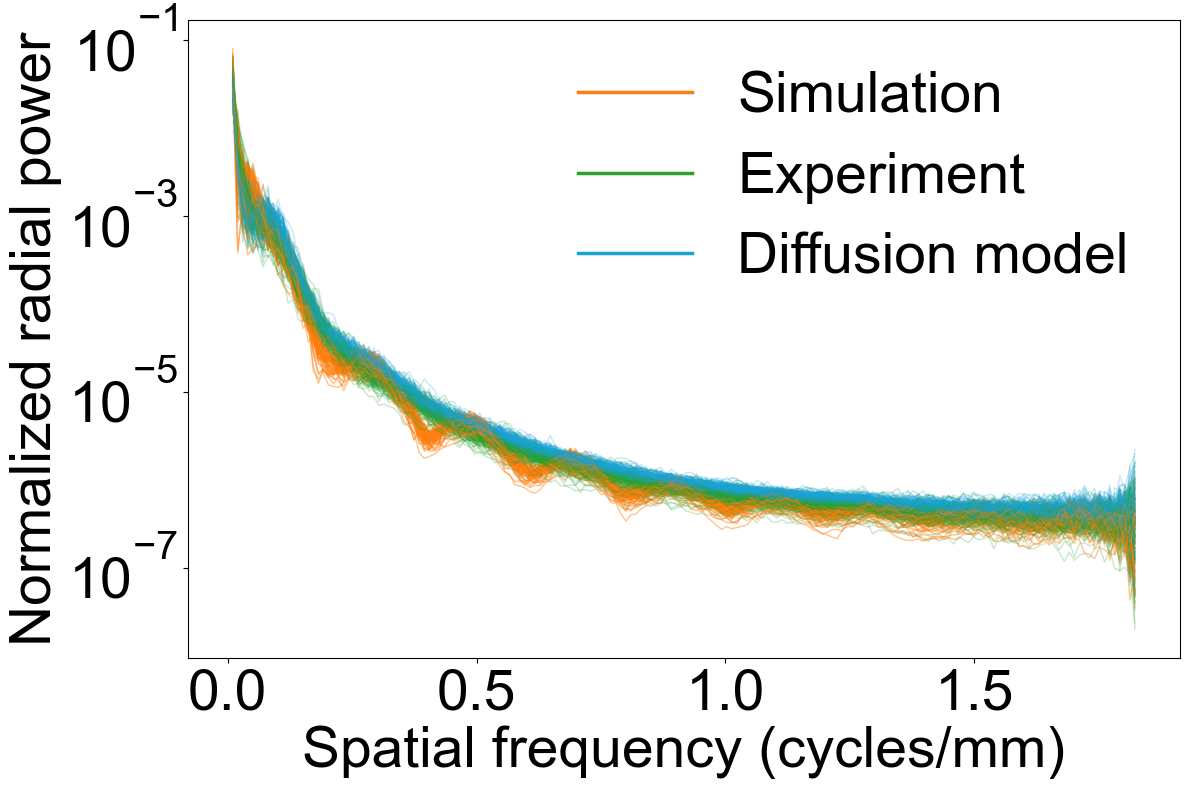

In [4]:
# Full 132-image comparison: normalized radial power versus spatial frequency.
# Fixed-set experimental replicates share their corresponding simulation output.
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
from scipy import ndimage

from cldm.config import (
    DIFFUSION_FOLDER_TEST_FIXED, EXP_FOLDER_TEST, EXP_FOLDER_TEST_FIXED, FPATH,
    MAIN_FOLDER, SIM_FOLDER_TEST, SIM_FOLDER_TEST_FIXED_OUTPUT,
)
from cldm.preprocess import (
    preprocess_experimental_backgroundblack_blackandwhite,
    preprocess_experimental_backgroundblack_blackandwhite_nocropping,
    preprocess_simulation,
)

fm.fontManager.addfont(str(FPATH))
ARIAL_FONT_NAME = fm.FontProperties(fname=str(FPATH)).get_name()
FOURIER_FONT_FAMILY = ARIAL_FONT_NAME
plt.rcParams['font.family'] = FOURIER_FONT_FAMILY


# 25.92 pixels/cm for 256x256 image-> 10/25.92 mm per pixel 
PIXEL_SIZE = 10 / 25.92 # mm per pixel # TO Do: change based on new calculations 
FREQ_UNIT = 'cycles/mm'
FOURIER_FONT_SIZE = 41
FOURIER_LABEL_FONTSIZE = FOURIER_FONT_SIZE
FOURIER_TICK_FONTSIZE = FOURIER_FONT_SIZE
FOURIER_LEGEND_FONTSIZE = FOURIER_FONT_SIZE
FOURIER_TRACE_OPACITY = 0.25
FULL_FOURIER_DIFFUSION_SAMPLE = 1
FULL_FOURIER_SIMULATION_THRESHOLD = 110
FULL_FOURIER_SIMULATION_BLUR_KERNEL = 5


def radial_power_spectrum_normalized(mask):
    pattern = np.asarray(mask, dtype=np.float64)
    pattern -= pattern.mean()

    fourier_transform = np.fft.fft2(pattern)
    power = np.abs(fourier_transform) ** 2
    power[0, 0] = 0  # remove the DC component
    non_dc_power = power.sum()
    if non_dc_power > 0:
        power /= non_dc_power

    power = np.fft.fftshift(power)
    height, width = power.shape
    center_y, center_x = height // 2, width // 2
    yy, xx = np.indices((height, width))
    radius = np.sqrt(
        (yy - center_y) ** 2 + (xx - center_x) ** 2
    ).astype(np.int32)
    radial_profile = ndimage.mean(
        power, labels=radius, index=np.arange(radius.max())
    )
    spatial_frequency = (
        np.arange(len(radial_profile)) / max(height, width) / PIXEL_SIZE
    )
    return spatial_frequency, radial_profile


regular_exp_files = {
    Path(filename).stem: filename for filename in os.listdir(EXP_FOLDER_TEST)
    if filename.lower().endswith(('.tif', '.tiff'))
}
regular_sim_files = {
    Path(filename).stem: filename for filename in os.listdir(SIM_FOLDER_TEST)
    if filename.lower().endswith(('.tif', '.tiff'))
}
regular_diffusion_files = {
    Path(filename).stem: filename for filename in os.listdir(MAIN_FOLDER)
    if filename.lower().endswith('.png')
}
regular_fourier_stems = sorted(
    regular_exp_files.keys() & regular_sim_files.keys() & regular_diffusion_files.keys(),
    key=lambda stem: tuple(int(part) for part in stem.split('_')),
)

fixed_exp_files = {
    Path(filename).stem: filename for filename in os.listdir(EXP_FOLDER_TEST_FIXED)
    if filename.lower().endswith(('.tif', '.tiff'))
}
fixed_diffusion_files = {
    filename.rsplit('_', 1)[0]: filename
    for filename in os.listdir(DIFFUSION_FOLDER_TEST_FIXED)
    if filename.lower().endswith('.png')
    and filename.endswith(f'_{FULL_FOURIER_DIFFUSION_SAMPLE}.png')
}
fixed_sim_files = {
    Path(filename).stem.split('_')[-1]: filename
    for filename in os.listdir(SIM_FOLDER_TEST_FIXED_OUTPUT)
    if filename.lower().endswith('.png')
}
fixed_fourier_stems = sorted(
    [
        stem for stem in fixed_exp_files.keys() & fixed_diffusion_files.keys()
        if stem.split('_')[1] in fixed_sim_files
    ],
    key=lambda stem: tuple(int(part) for part in stem.split('_')[1:]),
)
full_fourier_stems = regular_fourier_stems + fixed_fourier_stems
print(
    f'{len(full_fourier_stems)} matched images: '
    f'{len(regular_fourier_stems)} original + {len(fixed_fourier_stems)} fixed-seed'
)

fig, ax = plt.subplots(figsize=(12, 8))
source_colors = {
    'Simulation': 'tab:orange',
    'Experiment': 'tab:green',
    'Diffusion model': '#1AA3D6',
}

for image_number, stem in enumerate(full_fourier_stems, start=1):
    if stem.startswith('Fixed_'):
        experiment_path = os.path.join(EXP_FOLDER_TEST_FIXED, fixed_exp_files[stem])
        simulation_path = os.path.join(
            SIM_FOLDER_TEST_FIXED_OUTPUT, fixed_sim_files[stem.split('_')[1]]
        )
        diffusion_path = os.path.join(
            DIFFUSION_FOLDER_TEST_FIXED, fixed_diffusion_files[stem]
        )
    else:
        experiment_path = os.path.join(EXP_FOLDER_TEST, regular_exp_files[stem])
        simulation_path = os.path.join(SIM_FOLDER_TEST, regular_sim_files[stem])
        diffusion_path = os.path.join(MAIN_FOLDER, regular_diffusion_files[stem])

    experiment_mask = preprocess_experimental_backgroundblack_blackandwhite(
        experiment_path
    )
    diffusion_mask = preprocess_experimental_backgroundblack_blackandwhite_nocropping(
        diffusion_path
    )
    simulation_gray = preprocess_simulation(simulation_path)
    simulation_blurred = cv2.GaussianBlur(
        simulation_gray,
        (FULL_FOURIER_SIMULATION_BLUR_KERNEL, FULL_FOURIER_SIMULATION_BLUR_KERNEL),
        0,
    )
    simulation_mask = simulation_blurred > FULL_FOURIER_SIMULATION_THRESHOLD

    for label, mask in (
        ('Simulation', simulation_mask),
        ('Experiment', experiment_mask),
        ('Diffusion model', diffusion_mask),
    ):
        frequency, normalized_power = radial_power_spectrum_normalized(mask)
        ax.semilogy(
            frequency[1:], normalized_power[1:],
            color=source_colors[label], alpha=FOURIER_TRACE_OPACITY, linewidth=1.0,
        )

    if image_number % 20 == 0 or image_number == len(full_fourier_stems):
        print(f'Processed {image_number}/{len(full_fourier_stems)} matched images')

for label, color in source_colors.items():
    ax.plot([], [], color=color, linewidth=2.5, label=label)

ax.set_xlabel(f'Spatial frequency ({FREQ_UNIT})', fontsize=FOURIER_LABEL_FONTSIZE, fontfamily=FOURIER_FONT_FAMILY)
ax.set_ylabel('Normalized radial power', fontsize=FOURIER_LABEL_FONTSIZE, fontfamily=FOURIER_FONT_FAMILY)
ax.tick_params(axis='both', labelsize=FOURIER_TICK_FONTSIZE)
ax.legend(fontsize=FOURIER_LEGEND_FONTSIZE, prop={'family': FOURIER_FONT_FAMILY, 'size': FOURIER_LEGEND_FONTSIZE}, frameon=False)
fig.tight_layout()
plt.show()


In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 15B — normalized radial power spectra (132 images)
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig15B_fourier_spectra.pdf')
